# 1. The episode

- An episode is one light curve that contains the brightness of a star against time.
- This course uses the TESS 2-minute cadence.
- The benchmark is made by hiding synthetic transits in part of the dataset.
- The detection system is an LLM model with tools,model can only see the output of the tools, tools are designed to simulate astronomers available set of software.

The following cell loads an episode. It uses the real episode set `data/episodes/s98_v2`
if it is present, and a synthetic light curve with one injected planet otherwise.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path("..").resolve()))
sys.path.insert(0, str(Path("../tests").resolve()))
plt.rcParams["figure.figsize"] = (11, 3.5)  # matplolib configs
plt.rcParams["figure.dpi"] = 110  # matplotlib configs

EPISODES = Path("../data/episodes/s98_v2")


def load_episode(episode_id="ep_0001"):
    """Return (time, flux, truth) for one real episode, or a synthetic one if the set is absent."""
    if EPISODES.exists():
        from stargazer.episodes import EpisodeSet

        episode_set = EpisodeSet(EPISODES)
        time, flux, _ = episode_set.load(episode_id)
        return time, flux, episode_set.truth[episode_id]
    from conftest import synthetic_lc

    from stargazer.inject import inject, make_truth

    time, flux, _ = synthetic_lc(days=57.0)
    time = time - time.min()
    star = {"teff": 5500.0, "logg": 4.45, "radius_rsun": 0.95, "tmag": 10.0, "mass_msun": 0.95}
    truth = make_truth(period=0.7764, t0=0.1453, depth=0.0016, b=0.3, star=star)
    transit = {"period": truth.period, "t0": truth.t0, "duration": truth.duration, "depth": truth.depth}
    record = {"kind": "transit", "n_transits": 73, "snr": 60.0, "transit": transit}
    return time, inject(time, flux, truth), record


time, flux, truth = load_episode()
print(f"{len(time)} points over {time.max() - time.min():.1f} days; truth kind {truth['kind']}")

26521 points over 57.4 days; truth kind transit


## The raw light curve

time is represented in days and Flux is divided by median,
1.0 represents the star's normal brightness and 0.99 is one percent fainter and so on. A
transit refers to a dip below 1.0 that lasts hours and repeats at specific period.

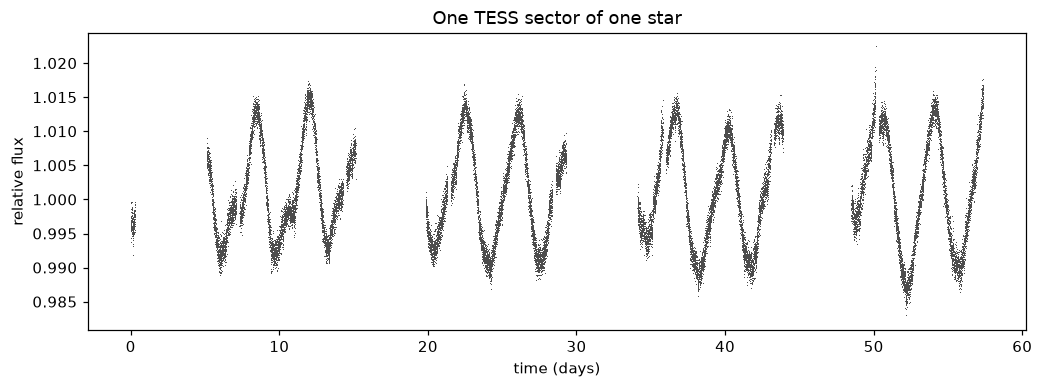

In [2]:
fig, axis = plt.subplots()
axis.plot(time, flux, ",", color="0.3")
axis.set_xlabel("time (days)")
axis.set_ylabel("relative flux")
axis.set_title("One TESS sector of one star")
plt.show()

## `summarize`

Generally model's first tool call is `summarize`.
It returns the numbers below:
- The point scatter is the white-noise level, parts per million (ppm); a transit must be well deeper than it.
- The flux range tells whether the star is active: a range far from 1.0 means spots or pulsation, which a period search can mistake for a planet. The gaps are the breaks in the data, for example the downlink in the middle of a sector.

In [3]:
from stargazer.tools import summarize

summary = summarize(time, flux)
for key, value in summary.items():
    print(f"{key:20s} {value}")

n_points             26521
span_days            57.372
cadence_minutes      2.0
point_scatter_ppm    1070.6
flux_min             0.982874
flux_max             1.022412
gaps_days            [[0.292, 4.835], [15.136, 4.708], [29.303, 4.8], [43.902, 4.589]]


# Visualising the transient dip

- The star's own variability swings the flux by a few percent over days.
- The injected transit is a dip of about 0.16 percent that lasts about an hour.
- At 57 days across the axis, transit is narrower than a pixel.

So the dip is both shallower than the variability and thinner than the above plot can draw.

The two panels shows below:
a zoom on one transit with the injected model drawn over the data,
and a fold of the whole episode at the true period.

In [4]:
from stargazer.inject import TransitTruth, transit_model
from stargazer.tools import fold

if truth["kind"] == "transit":
    record = TransitTruth.from_dict(truth["transit"])
    swing_ppm = (np.nanpercentile(flux, 99) - np.nanpercentile(flux, 1)) * 1e6
    print(f"variability swing (1st to 99th percentile): {swing_ppm:8.0f} ppm")
    print(f"injected depth:                             {record.depth * 1e6:8.0f} ppm")
    print(f"transit duration:                           {record.duration * 24:8.2f} hours")
    print(f"transits in the episode:                    {truth['n_transits']:8d}")
    print(f"fraction of the axis one transit covers:    {record.duration / (time.max() - time.min()):8.4f}")

variability swing (1st to 99th percentile):    26995 ppm
injected depth:                                 1586 ppm
transit duration:                               1.34 hours
transits in the episode:                          48
fraction of the axis one transit covers:      0.0010


/home/siddharth899/personal_code/star_finder/.venv/lib/python3.13/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


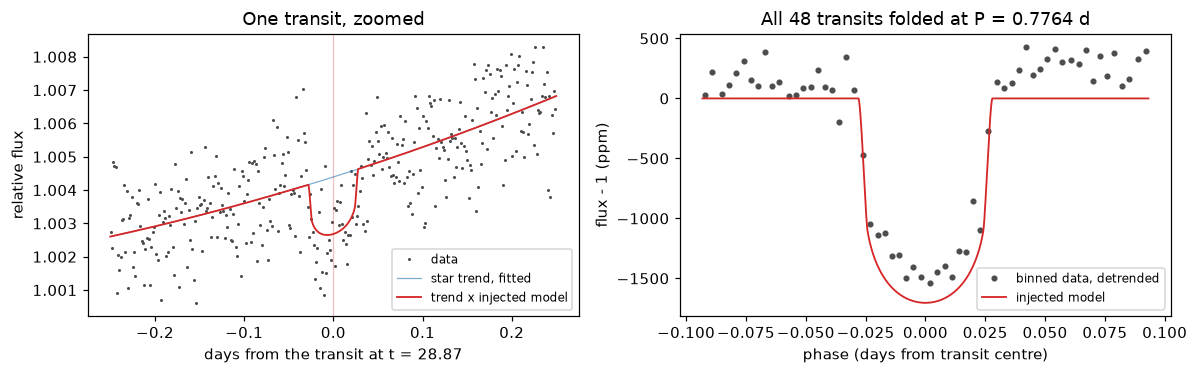

In [5]:
if truth["kind"] == "transit":
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.5))

    # Left: zoom on one transit near the middle of the sector, with the model on top.
    n_centres = int((time.max() - record.t0) / record.period) + 1
    centres = record.t0 + record.period * np.arange(n_centres)
    centre = centres[np.argmin(np.abs(centres - np.nanmedian(time)))]
    window = np.abs(time - centre) < 0.25
    out_of_transit = window & (np.abs(time - centre) > 0.75 * record.duration)
    baseline = np.polynomial.Polynomial.fit(time[out_of_transit] - centre, flux[out_of_transit], deg=2)
    grid = np.linspace(centre - 0.25, centre + 0.25, 2000)
    left.plot(time[window] - centre, flux[window], ".", ms=2, color="0.3", label="data")
    left.plot(
        grid - centre,
        baseline(grid - centre),
        color="tab:blue",
        lw=0.8,
        alpha=0.6,
        label="star trend, fitted",
    )
    left.plot(
        grid - centre,
        baseline(grid - centre) * transit_model(grid, record),
        color="tab:red",
        lw=1.2,
        label="trend x injected model",
    )
    left.axvline(0.0, color="tab:red", alpha=0.3, lw=0.8)
    left.set_xlabel(f"days from the transit at t = {centre:.2f}")
    left.set_ylabel("relative flux")
    left.set_title("One transit, zoomed")
    left.legend(loc="lower right", fontsize=8)

    # Right: fold every transit on top of each other with the detector's own tool.
    folded = fold(time, flux, record.period, record.t0, n_bins=60, phase_half_width=0.12)
    phase_grid = np.linspace(-0.12, 0.12, 2000) * record.period
    right.plot(folded["phase"], folded["flux_ppm"], "o", ms=3, color="0.3", label="binned data, detrended")
    right.plot(
        phase_grid,
        (transit_model(record.t0 + phase_grid, record) - 1.0) * 1e6,
        color="tab:red",
        lw=1.2,
        label="injected model",
    )
    right.set_xlabel("phase (days from transit centre)")
    right.set_ylabel("flux - 1 (ppm)")
    right.set_title(f"All {truth['n_transits']} transits folded at P = {record.period:.4f} d")
    right.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()

## How the injection works

The benchmark multiplies the real light curve by a transit model:

$$
F_\mathrm{out}(t) = F_\mathrm{in}(t) \times m(t), \qquad m(t) = 1 \text{ out of transit.}
$$

The product leaves the noise and the stellar variability untouched outside the transits. Inside a
transit, the noise scales with the model. The model $m(t)$ comes from batman (Kreidberg 2015).

### The geometry

The builder draws four free parameters: the period $P$, the epoch $t_0$, the geometric depth
$\delta$ and the impact parameter $b$. `make_truth` derives the rest from the host star's surface
gravity $g$, radius $R_\star$ and effective temperature $T_\mathrm{eff}$.

| quantity | equation | meaning |
|---|---|---|
| radius ratio | $k = R_p / R_\star = \sqrt{\delta}$ | the depth is the area ratio of the two discs |
| stellar mass | $M_\star = g R_\star^2 / G$ | from the catalogue gravity and radius |
| scaled semi-major axis | $\dfrac{a}{R_\star} = \dfrac{1}{R_\star}\left(\dfrac{G M_\star P^2}{4\pi^2}\right)^{1/3}$ | Kepler's third law for a planet of negligible mass |
| inclination | $i = \arccos\!\left(\dfrac{b\,R_\star}{a}\right)$ | $b$ is the projected distance from the disc centre at mid-transit, in stellar radii |
| duration | $T_{14} = \dfrac{P}{\pi}\arcsin\!\left(\dfrac{\sqrt{(1+k)^2 - b^2}}{(a/R_\star)\sin i}\right)$ | first to fourth contact, circular orbit (Seager and Mallén-Ornelas 2003) |

### The shape

At each time stamp batman computes the projected separation of the planet from the disc centre,
in stellar radii, for a circular orbit with orbital phase $\phi = (t - t_0)/P$:

$$
z(t) = \frac{a}{R_\star}\sqrt{\sin^2(2\pi\phi) + \cos^2 i\,\cos^2(2\pi\phi)}.
$$

The planet is on the disc when $z < 1 + k$. The star is not uniformly bright. Its surface follows
the quadratic limb-darkening law

$$
\frac{I(\mu)}{I(1)} = 1 - u_1(1-\mu) - u_2(1-\mu)^2,
\qquad \mu = \sqrt{1 - r^2},
$$

where $r$ is the distance from the disc centre in stellar radii and $\mu$ is the cosine of the
viewing angle. The coefficients $u_1, u_2$ come from a table by $T_\mathrm{eff}$ (Claret 2017).
The model flux is one minus the blocked fraction of the limb-darkened disc:

$$
m(t) = 1 - \frac{\displaystyle\iint_{\text{covered}} I(\mu)\,\mathrm{d}A}{\displaystyle\iint_{\text{disc}} I(\mu)\,\mathrm{d}A}.
$$

Two consequences follow. The disc centre is brighter than the limb, so a central transit ($b = 0$)
is a little deeper than $\delta$ and has a flat bottom. A transit near the limb ($b$ close to 1) is
shorter and rounder. The figure below draws the three pieces for this episode's transit.

![One transit in three steps](figures/transit_shape.png)

**1. The path.** The orange disc is star system as we see it. It is bright at the centre and dark towards
the edge. That is refered as limb darkening, the $I(\mu)$ law. The planet is the black dot, 0.04 stellar
radii across, so $k = 0.04$. It moves along the red line. The red line misses the centre by
$b = 0.66$ stellar radii,is the impact parameter. The dashed blue line is a planet that
crosses the centre, for comparison.

**2. The distance.** This panel follows the planet for two hours either side of the transit
centre. The curve is $z(t)$: how far the planet is from the disc centre. The dotted line is the
edge of the star. While the curve is below it, the planet is in front of the star and blocks light.
The shaded span is the transit. Its width is the duration $T_{14}$, about 1.3 hours. The lowest
point of the curve is $b$.

**3. The dip.** This is $m(t)$, the light the planet blocks. The red curve is this transit. The
blue one is the central path with the same planet. The dotted line is $k^2$, the planet's area
over the star's area.The central path goes deeper than $k^2$ because it
hides the bright centre. This transit is shorter because its chord near the limb is short, and
rounder because the planet never fully leaves the darker part of the disc.

The benchmark multiplies the real light curve by the red curve at every transit. The next cell
rebuilds the model from the stored truth data and checks the depth and the duration against the numbers.

In [11]:
if truth["kind"] == "transit":
    fine = record.t0 + np.linspace(-record.duration, record.duration, 20001)
    model = transit_model(fine, record)
    in_transit = fine[model < 1.0]
    print(f"geometric depth delta = k^2:   {record.depth * 1e6:8.0f} ppm")
    print(f"model central depth:          {(1 - model.min()) * 1e6:8.0f} ppm  (deeper: limb darkening)")
    print(f"stored duration T14:          {record.duration * 24:8.2f} hours")
    print(f"model first to fourth contact:{(in_transit.max() - in_transit.min()) * 24:8.2f} hours")
    print(f"impact parameter b:           {record.b:8.2f}")
    print(f"a / R*:                       {record.a_rs:8.2f}")
    print(f"inclination:                  {record.inc_deg:8.2f} degrees")
    print(f"limb darkening u1, u2:        {record.u1:.2f}, {record.u2:.2f}")

geometric depth delta = k^2:       1586 ppm
model central depth:              1704 ppm  (deeper: limb darkening)
stored duration T14:              1.34 hours
model first to fourth contact:    1.34 hours
impact parameter b:               0.66
a / R*:                           3.66
inclination:                     79.67 degrees
limb darkening u1, u2:        0.40, 0.25
